In [1]:
# Cell 2 - Imports
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [5]:
# Cell 4 - Fetch GSE69091  from GEO
GSE69091 = GEOparse.get_GEO(geo='GSE69091', destdir='./data/raw/', how='full')

06-Mar-2026 10:40:50 DEBUG utils - Directory ./data/raw/ already exists. Skipping.
06-Mar-2026 10:40:50 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE69nnn/GSE69091/soft/GSE69091_family.soft.gz to ./data/raw/GSE69091_family.soft.gz
100%|██████████| 22.1M/22.1M [00:39<00:00, 581kB/s]   
06-Mar-2026 10:41:32 DEBUG downloader - Size validation passed
06-Mar-2026 10:41:32 DEBUG downloader - Moving C:\Users\acer\AppData\Local\Temp\tmp6tteiwdv to C:\Users\acer\SCLC Project\data\raw\GSE69091_family.soft.gz
06-Mar-2026 10:41:32 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE69nnn/GSE69091/soft/GSE69091_family.soft.gz
06-Mar-2026 10:41:32 INFO GEOparse - Parsing ./data/raw/GSE69091_family.soft.gz: 
06-Mar-2026 10:41:32 DEBUG GEOparse - DATABASE: GeoMiame
06-Mar-2026 10:41:32 DEBUG GEOparse - SERIES: GSE69091
06-Mar-2026 10:41:32 DEBUG GEOparse - PLATFORM: GPL16570
D:\Anaconda\Lib\site-packages\GEOparse\GEOparse.py:401: DtypeWarning: Co

In [9]:
print(GSE69091.metadata)

{'title': ['Expression data from a mouse small cell lung cancer (SCLC) cell line, KP1, transfected with Notch-ICD'], 'geo_accession': ['GSE69091'], 'status': ['Public on May 21 2015'], 'submission_date': ['May 20 2015'], 'last_update_date': ['Feb 21 2018'], 'pubmed_id': ['26168399'], 'summary': ['Transient transfection of activated Notch1 (Notch1-ICD) decreases cellular proliferation and reduces the expression of a subset of neuroendocrine genes.', 'We used microarrays to identify the gene expression changes 48 hours after overexpression of Notch1-ICD.'], 'overall_design': ['mSCLC cells transfected with Notch1-ICD-ires-GFP were FACS sorted for GFP+ cells 48 hours after transfection. RNA was then extracted and hybridized to Affymetrix GeneChipÂ® Mouse Gene 2.0 ST array.'], 'type': ['Expression profiling by array'], 'contributor': ['Jing,S,Lim', 'Julien,,Sage'], 'sample_id': ['GSM1692708', 'GSM1692709', 'GSM1692710', 'GSM1692711', 'GSM1692712', 'GSM1692713'], 'contact_name': ['Julien,,Sa

In [11]:
# Cell 6 - Inspect samples
for gsm_name, gsm in GSE69091.gsms.items():
    print(gsm_name, gsm.metadata['title'])

GSM1692708 ['Empty vector transfected cells, biological  rep1']
GSM1692709 ['Empty vector transfected cells, biological  rep2']
GSM1692710 ['Empty vector transfected cells, biological  rep3']
GSM1692711 ['Notch1-ICD transfected cells, biological rep 1']
GSM1692712 ['Notch1-ICD transfected cells, biological rep 2']
GSM1692713 ['Notch1-ICD transfected cells, biological rep 3']


In [15]:
# Cell 7 - Inspect a single sample to understand data structure
sample = list(GSE69091.gsms.values())[0]
print(sample.table.head())
print(sample.table.shape)

     ID_REF     VALUE
0  17229036  4.837118
1  17229020  5.665051
2  17498502  6.613848
3  17462145  4.801978
4  17253656  5.226386
(41345, 2)


In [17]:
# Cell 8 - Build expression matrix for SCLC and Normal samples only
samples_of_interest = {}

for gsm_id, gsm in GSE69091.gsms.items():
    title = gsm.metadata['title'][0]
    if 'Empty vector' in title:
        samples_of_interest[gsm_id] = 'Control'
    elif 'Notch1-ICD' in title:
        samples_of_interest[gsm_id] = 'Notch_ICD'

print('Selected samples:')
for gsm_id, group in samples_of_interest.items():
    print(f' {gsm_id}: {group}')

print(f'\nTotal: {len(samples_of_interest)}samples')

Selected samples:
 GSM1692708: Control
 GSM1692709: Control
 GSM1692710: Control
 GSM1692711: Notch_ICD
 GSM1692712: Notch_ICD
 GSM1692713: Notch_ICD

Total: 6samples


In [23]:
# Cell 9 - Inspect platform annotation
platform = list(GSE69091.gpls.values())[0]
print(platform.table.head())
print(platform.table.columns.tolist())

         ID  probeset_id                  SPOT_ID seqname strand      start  \
0  17210850   17210850.0  chr1(+):3102016-3102125    chr1      +  3102016.0   
1  17210852   17210852.0  chr1(+):3466587-3513553    chr1      +  3466587.0   
2  17210855   17210855.0  chr1(+):4807823-4846739    chr1      +  4807823.0   
3  17210869   17210869.0  chr1(+):4857694-4897909    chr1      +  4857694.0   
4  17210883   17210883.0  chr1(+):4970857-4976820    chr1      +  4970857.0   

        stop  total_probes                                    gene_assignment  \
0  3102125.0           8.0                                                ---   
1  3513553.0          23.0                                                ---   
2  4846739.0          20.0  NM_008866 // Lypla1 // lysophospholipase 1 // ...   
3  4897909.0          21.0  NM_001159751 // Tcea1 // transcription elongat...   
4  4976820.0          23.0                                                ---   

                                     m

In [25]:
# Create a copy first - never modify platform.table directly
annotation = platform.table[['ID', 'gene_assignment']].copy()

# Extract gene symbol from gene_assignment
annotation['Gene Symbol'] = annotation['gene_assignment'].apply(
    lambda x: x.split('//')[1].strip() if '//' in str(x) and x != '---' else None
)

print(f"Unannotated probes: {annotation['Gene Symbol'].isna().sum()}")
print(f"Annotated probes: {annotation['Gene Symbol'].notna().sum()}")
print(annotation[['ID', 'Gene Symbol']].head(10))

Unannotated probes: 14764
Annotated probes: 27037
         ID Gene Symbol
0  17210850        None
1  17210852        None
2  17210855      Lypla1
3  17210869       Tcea1
4  17210883        None
5  17210887     Atp6v1h
6  17210904       Oprk1
7  17210912      Rb1cc1
8  17210947     Fam150a
9  17210953        St18


In [29]:
# Check for any remaining multi-gene indicators
print(annotation['Gene Symbol'].str.contains('///', na=False).sum())
print(annotation['Gene Symbol'].str.contains(' /// ', na=False).sum())

0
0


In [31]:
# Check for multiple gene assignments in the raw gene_assignment column
multi_gene_raw = annotation['gene_assignment'].str.contains(' /// ', na=False).sum()
print(f"Probes with multiple gene assignments: {multi_gene_raw}")

# Show an example if any exist
if multi_gene_raw > 0:
    print(annotation[annotation['gene_assignment'].str.contains(' /// ', na=False)]['gene_assignment'].head(3))

Probes with multiple gene assignments: 23516
2    NM_008866 // Lypla1 // lysophospholipase 1 // ...
3    NM_001159751 // Tcea1 // transcription elongat...
5    NM_133826 // Atp6v1h // ATPase, H+ transportin...
Name: gene_assignment, dtype: object


In [33]:
# Look at a few examples with /// to understand the pattern
multi_examples = annotation[annotation['gene_assignment'].str.contains(' /// ', na=False)]['gene_assignment'].head(5)
for example in multi_examples:
    print(example)
    print("---")

NM_008866 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000027036 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// BC013536 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// BC052848 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// U89352 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// CT010201 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000134384 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000150971 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000134384 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000155020 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000141278 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// AK050549 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// AK167231 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000115529 // Lypla1 // lysophospholipase 1 // 1 A1|1 // 18777 /// ENSMUST00000137887 //

In [37]:
print(annotation.columns.tolist())
print(annotation.head())

['ID', 'gene_assignment', 'Gene Symbol']
         ID                                    gene_assignment Gene Symbol
0  17210850                                                ---        None
1  17210852                                                ---        None
2  17210855  NM_008866 // Lypla1 // lysophospholipase 1 // ...      Lypla1
3  17210869  NM_001159751 // Tcea1 // transcription elongat...       Tcea1
4  17210883                                                ---        None


In [43]:
# Cell 10 - Build annotated expression matrix
# Step 1 - Build raw matrix
expr_matrix = pd.DataFrame()
for gsm_id in samples_of_interest.keys():
    sample = GSE69091.gsms[gsm_id]
    df = sample.table.set_index('ID_REF')['VALUE']
    df.name = gsm_id
    expr_matrix = pd.concat([expr_matrix, df], axis=1)
    
# After Step 1 - check index type
print(f"expr_matrix index type: {expr_matrix.index.dtype}")
print(f"annotation ID type: {annotation['ID'].dtype}")
print(f"expr_matrix index sample: {expr_matrix.index[:5].tolist()}")
print(f"annotation ID sample: {annotation['ID'][:5].tolist()}")

# Step 2 - Get annotation (already created as a copy)
ann = annotation[['ID', 'Gene Symbol']].copy()

# Step 3 - Remove unannotated probes
ann = ann[ann['Gene Symbol'].notna()]
ann = ann[ann['Gene Symbol'] != '']
ann = ann[ann['Gene Symbol'] != 'None']

# Step 4 - No /// filter needed for this dataset
# (/// separates transcripts of same gene, not different genes)

# Step 5 - Merge (convert annotation ID to string first)
ann['ID'] = ann['ID'].astype(str)
expr_matrix.index.name = 'ID'
expr_matrix = expr_matrix.merge(ann, left_index=True, right_on='ID')
expr_matrix = expr_matrix.set_index('Gene Symbol').drop(columns='ID')

# Step 6 - Collapse duplicates by mean
expr_matrix = expr_matrix.groupby('Gene Symbol').mean()

print(expr_matrix.shape)
print(expr_matrix.head())

expr_matrix index type: object
annotation ID type: object
expr_matrix index sample: ['17229036', '17229020', '17498502', '17462145', '17253656']
annotation ID sample: [17210850, 17210852, 17210855, 17210869, 17210883]
(24647, 6)
               GSM1692708  GSM1692709  GSM1692710  GSM1692711  GSM1692712  \
Gene Symbol                                                                 
0610005C13Rik    5.890619    5.519774    5.660486    5.789033    5.749963   
0610007C21Rik    8.830097    8.883964    8.813685    9.089290    9.238624   
0610007L01Rik   10.128110    9.905262    9.920422    9.953181    9.891114   
0610007N19Rik    4.610350    4.528474    4.406695    5.159367    5.396796   
0610007P08Rik    8.125562    8.078844    8.354414    7.939124    7.873424   

               GSM1692713  
Gene Symbol                
0610005C13Rik    5.656935  
0610007C21Rik    9.149483  
0610007L01Rik    9.882555  
0610007N19Rik    5.000176  
0610007P08Rik    8.081083  


In [45]:
# Cell 11 - Check for NA values
print(f'Total NA values: {expr_matrix.isna().sum().sum()}')
print(f'\nNa value per sample:')
print(expr_matrix.isna().sum())

Total NA values: 0

Na value per sample:
GSM1692708    0
GSM1692709    0
GSM1692710    0
GSM1692711    0
GSM1692712    0
GSM1692713    0
dtype: int64


In [47]:
expr_matrix.to_csv('./data/processed/GSE69091_expression_matrix.csv')
print('Expression matirx saved!')

Expression matirx saved!


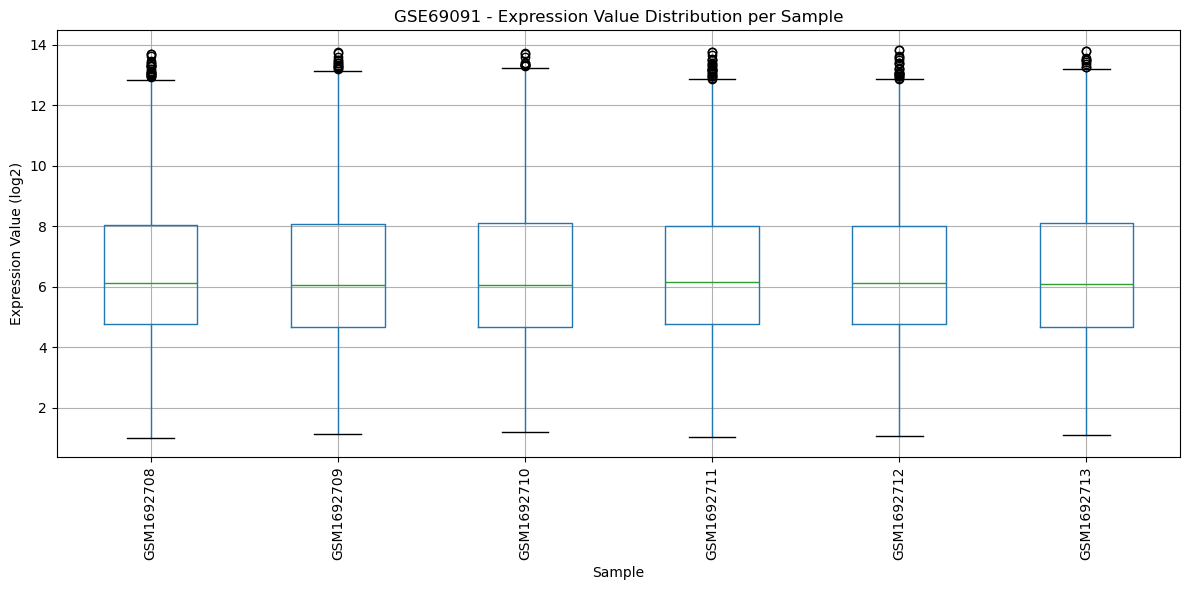

In [49]:
# Cell 13 - Sample distribution boxplot
plt.figure(figsize=(12, 6))
expr_matrix.boxplot(rot=90)
plt.title('GSE69091 - Expression Value Distribution per Sample')
plt.ylabel('Expression Value (log2)')
plt.xlabel('Sample')
plt.tight_layout()
plt.savefig('./figures/GSE69091_boxplot.png', dpi=300)
plt.show()

In [51]:
# Cell 14 - Create metadata dataframe
metadata = pd.DataFrame({
    'sample_id' : list(samples_of_interest.keys()),
    'group': list(samples_of_interest.values())
})
metadata = metadata.set_index('sample_id')
metadata.to_csv('./data/processed/GSE69091_metadata.csv')
print(metadata)

                group
sample_id            
GSM1692708    Control
GSM1692709    Control
GSM1692710    Control
GSM1692711  Notch_ICD
GSM1692712  Notch_ICD
GSM1692713  Notch_ICD


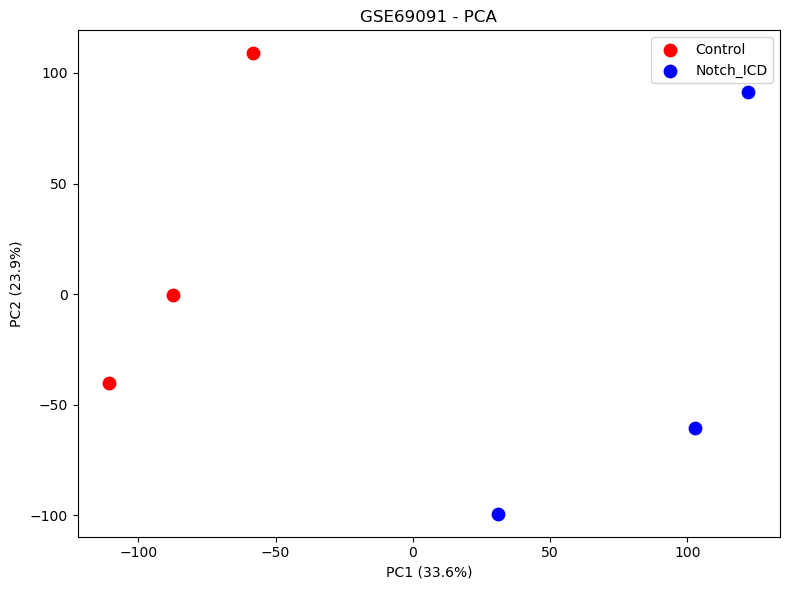

In [57]:
# Cell 15 - PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize the data
scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix.T)

# Run PCA
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

# Plot
plt.figure(figsize=(8, 6))
colors = {'Control': 'red', 'Notch_ICD': 'blue'}
for group in ['Control', 'Notch_ICD']:
    mask = metadata['group'] == group
    plt.scatter(pca_coords[mask, 0], pca_coords[mask, 1],
                c=colors[group], label=group, s=80)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE69091 - PCA')
plt.legend()
plt.tight_layout()
plt.savefig('./figures/GSE69091_PCA.png', dpi=300)
plt.show()